# Tarea 2 · Parte 1 – Corpus y extracción (OCR + ASR)

**Pregunta guía:** ¿podemos convertir documentos escaneados y entrevistas en audio peruanas en un archivo de texto estructurado y buscable?

| | |
|---|---|
| **Fecha de descarga del corpus** | 22 de octubre de 2026 (`corpus.py`) |
| **Fecha de extracción OCR y ASR** | 23 de octubre de 2026 (`extraccion.py` + este notebook) |
| **Fuente** | Wikimedia Commons, para los 48 archivos (descarga con User-Agent descriptivo y pausas de 2 s) |
| **Licencias: 25 documentos** | 10 dominio público · 5 CC0 · 1 CC BY 4.0 · 2 CC BY-SA 3.0 · 7 CC BY-SA 4.0 |
| **Licencias: 23 clips de audio** | 23 CC BY-SA 4.0 (42,4 min) |
| **OCR** | PaddleOCR 3.7.0 sobre PaddlePaddle 3.2.2 (motor nativo, CPU): detector `PP-OCRv6_medium_det` + reconocedor `PP-OCRv6_medium_rec` (multilingüe, reconoce tildes y ñ) |
| **ASR** | faster-whisper 1.2.1 con el modelo `small` (CTranslate2, int8 en CPU), idioma fijado en `es`, beam 5, VAD de Silero activado |
| **Diarización** | Huellas de voz WeSpeaker ResNet34 (`pyannote/wespeaker-voxceleb-resnet34-LM`, pyannote.audio 4.0.7) + clustering jerárquico (`voz.diarizar`) |
| **Detección de nombres** | NER `mrm8488/bert-spanish-cased-finetuned-ner` (transformers 5.20.2) + revisión manual |
| **Entorno** | Python 3.12, `uv sync` sobre `tarea_2/pyproject.toml` (reúne los grupos `docai` y `audio` de las sesiones 10 y 13), solo CPU |

El detalle de cada archivo (URL, licencia, autor y cómo recuperarlo) está en `datos/fuentes.csv` y se muestra más abajo. Los archivos originales, los respaldos crudos del OCR y del ASR y el diccionario de seudónimos quedan en `datos/raw/`, que no se versiona.

**Cómo se ejecutó.** La laptop tiene 8 GB de RAM, así que el OCR y el ASR se corrieron por tandas desde la terminal con `uv run python extraccion.py ocr|asr`. Ese módulo deja un respaldo crudo por archivo y este notebook llama a las mismas funciones: si un archivo ya tiene respaldo, lo lee en lugar de volver a correr el modelo. Los tiempos que se reportan son los de la corrida real, guardados en cada respaldo.

In [1]:
import hashlib
import json
import re
import sys
import warnings
from io import BytesIO
from pathlib import Path

warnings.filterwarnings("ignore")

import pandas as pd
import plotly.express as px
import plotly.io as pio
from IPython.display import Image as Imagen, display
from PIL import Image

import extraccion as ex
import voz

# Plotly interactivo + imagen estática (para que los gráficos se vean en GitHub)
pio.renderers.default = "plotly_mimetype+png"
pio.defaults.default_width, pio.defaults.default_height = 1000, 500
pd.set_option("display.max_colwidth", 110)

DATOS = Path("datos")
COLORES = {"impreso": "#2a78d6", "foto": "#eb6834", "manuscrito": "#52514e"}

import faster_whisper, paddle, paddleocr, pyannote.audio, transformers
print(f"Python {sys.version.split()[0]} · PaddleOCR {paddleocr.__version__} · PaddlePaddle {paddle.__version__}")
print(f"faster-whisper {faster_whisper.__version__} · pyannote.audio {pyannote.audio.__version__} · transformers {transformers.__version__}")
print("OCR:", ex.nombre_modelo_ocr())
print("ASR:", ex.nombre_modelo_asr())

Python 3.12.15 · PaddleOCR 3.7.0 · PaddlePaddle 3.2.2
faster-whisper 1.2.1 · pyannote.audio 4.0.7 · transformers 5.20.2
OCR: PaddleOCR 3.7.0 (PP-OCRv6_medium_det + PP-OCRv6_medium_rec, CPU, sin preprocesamiento)
ASR: faster-whisper 1.2.1 small (CPU int8, beam 5, VAD Silero on, idioma=es)


## 1. Corpus y fuentes

Se trabajan solo los tres tipos de documento pedidos (8 impresos nítidos, 8 fotos con sombra, reflejo o inclinación y 9 manuscritos) y entrevistas o lecturas en español peruano. **Todo viene de Wikimedia Commons con licencia libre**: no hay texto sintético ni grabaciones propias.

Siete entrevistas (clip_009 a clip_015) llevaban en el nombre del archivo de Commons el nombre de la persona entrevistada o del estudiante que entrevista. Para no publicarlo, `corpus.py` las pide por su número de página (`curid`), su `fuente_url` usa el enlace `https://commons.wikimedia.org/?curid=…` y su título queda seudonimizado.

In [2]:
fuentes = pd.read_csv(DATOS / "fuentes.csv")
docs = pd.read_csv(DATOS / "raw/documentos/catalogo.csv")[["id", "tipo", "descripcion", "archivo", "licencia"]]
clips = pd.read_csv(DATOS / "raw/audio/catalogo.csv")[["id", "descripcion", "archivo_audio", "recorte", "duracion_seg", "licencia"]]

print(f"{len(docs)} documentos · {len(clips)} clips · {clips.duracion_seg.sum() / 60:.1f} min de audio")
display(pd.crosstab(fuentes.licencia, fuentes.modalidad, margins=True, margins_name="total"))
fuentes[["id", "modalidad", "licencia", "autor", "fuente_url"]].sample(6, random_state=1)

25 documentos · 23 clips · 42.4 min de audio


modalidad,audio,documento,total
licencia,,,
CC BY 4.0,0,1,1
CC BY-SA 3.0,0,2,2
CC BY-SA 4.0,23,7,30
CC0,0,5,5
Public domain,0,10,10
total,23,25,48


,id,modalidad,licencia,autor,fuente_url
33,clip_009,audio,CC BY-SA 4.0,Hellloff233,https://commons.wikimedia.org/?curid=133964620
23,doc_024,documento,Public domain,José Balta,https://commons.wikimedia.org/wiki/File:AR-ANH-EF-Secc.II-67.jpg
38,clip_014,audio,CC BY-SA 4.0,Rashelley Perez,https://commons.wikimedia.org/?curid=149433723
36,clip_012,audio,CC BY-SA 4.0,QM Keen,https://commons.wikimedia.org/?curid=121219891
2,doc_003,documento,CC0,Ing. Oswaldo Jiménez Salas,https://commons.wikimedia.org/wiki/File:Otorgamiento_Municipal.jpg
3,doc_004,documento,CC BY-SA 4.0,El Peruano,https://commons.wikimedia.org/wiki/File:NOMBRAMIENTO_JAVIER_DAVID_HABICH.pdf


## 2. Limpieza: duplicados, documentos ilegibles y audios sin voz

Hay tres controles antes de publicar nada:

1. **Duplicados por hash**: SHA-256 de cada imagen y de cada audio original. Dos archivos con el mismo hash son el mismo archivo aunque tengan nombre distinto.
2. **Documentos ilegibles**: se descarta un documento si el OCR no detecta ninguna línea de texto. Los manuscritos difíciles se **conservan** como casos difíciles para la Parte 2, porque una persona sí los puede leer.
3. **Audios sin voz**: el VAD (Silero) mide cuántos segundos de cada clip tienen voz. Un clip con voz en menos del 25 % de su duración se marca para escucharlo, y se descarta si la revisión confirma que no hay habla útil.

In [3]:
def sha256(ruta):
    return hashlib.sha256(Path(ruta).read_bytes()).hexdigest()


hashes = pd.concat([
    pd.DataFrame({"id": docs.id, "hash": docs.archivo.map(sha256)}),
    pd.DataFrame({"id": clips.id, "hash": [sha256(next((DATOS / "raw/audio/originales").glob(f"{i}.*"))) for i in clips.id]}),
])
duplicados = hashes[hashes.duplicated("hash", keep=False)]
print(f"Archivos revisados: {len(hashes)} · hashes distintos: {hashes.hash.nunique()} · duplicados: {len(duplicados)}")

Archivos revisados: 48 · hashes distintos: 48 · duplicados: 0


## 3. OCR de los 25 documentos (Sesión 10)

**Parámetros:** la configuración base de PaddleOCR, sin personalización:
- **Modelos:** `PP-OCRv6_medium_det` para detectar las líneas y `PP-OCRv6_medium_rec` para leerlas.
- **Idioma:** el modelo por defecto es multilingüe y lee el español con tildes, ñ y signos `¿¡`, por eso no se fijó `lang`.
- **Preprocesamiento:** ninguno. Están apagados `use_doc_orientation_classify` (girar la página), `use_doc_unwarping` (aplanar hojas curvas) y `use_textline_orientation` (girar cada línea). Así se mide cómo responde el modelo base a las fotos inclinadas y con sombra.
- **Motor:** el nativo de Paddle en CPU. Con `engine="transformers"` (PyTorch) la misma página tardó 280 s, contra 48 s con Paddle, y el texto fue idéntico.

**Respaldo crudo**, en `datos/raw/documentos/`:
- `ocr/doc_XXX.json`: líneas, confianza y cajas de cada línea.
- `recortes/doc_XXX/`: la imagen con las cajas detectadas y un recorte por línea.

In [4]:
pendientes = [i for i in docs.id if not (ex.DOCS / "ocr" / f"{i}.json").exists()]
modelo_ocr = ex.cargar_ocr() if pendientes else None          # solo se carga si falta algún documento
ocr = {i: ex.ocr_documento(i, modelo_ocr) for i in docs.id}

docs["texto_ocr_crudo"] = docs.id.map(lambda i: "\n".join(ocr[i]["lineas"]))
docs["lineas"] = docs.id.map(lambda i: len(ocr[i]["lineas"]))
docs["confianza_media"] = docs.id.map(lambda i: round(sum(ocr[i]["confianzas"]) / max(1, len(ocr[i]["confianzas"])), 3))
docs["segundos_ocr"] = docs.id.map(lambda i: ocr[i]["segundos"])

ilegibles = docs[docs.lineas == 0]
print(f"Documentos sin texto detectado (ilegibles): {len(ilegibles)}")
print(f"Tiempo total de OCR: {docs.segundos_ocr.sum() / 60:.1f} min ({docs.segundos_ocr.mean():.0f} s por página en CPU)")
docs.groupby("tipo").agg(documentos=("id", "size"), lineas=("lineas", "median"),
                         confianza_media=("confianza_media", "mean"), segundos=("segundos_ocr", "mean")).round(2)

Documentos sin texto detectado (ilegibles): 0
Tiempo total de OCR: 15.4 min (37 s por página en CPU)


,documentos,lineas,confianza_media,segundos
tipo,,,,
foto,8,12.0,0.96,26.82
impreso,8,35.5,0.97,50.24
manuscrito,9,22.0,0.70,33.94


La **confianza** que reporta el reconocedor ya anticipa dónde fallará: en impresos y fotos ronda 0,96–0,97, pero en manuscritos baja a 0,70. Ejemplo de lo que guarda el respaldo: la imagen con las cajas detectadas de una placa de bronce fotografiada en ángulo (doc_010). A la derecha está el texto que leyó el modelo.

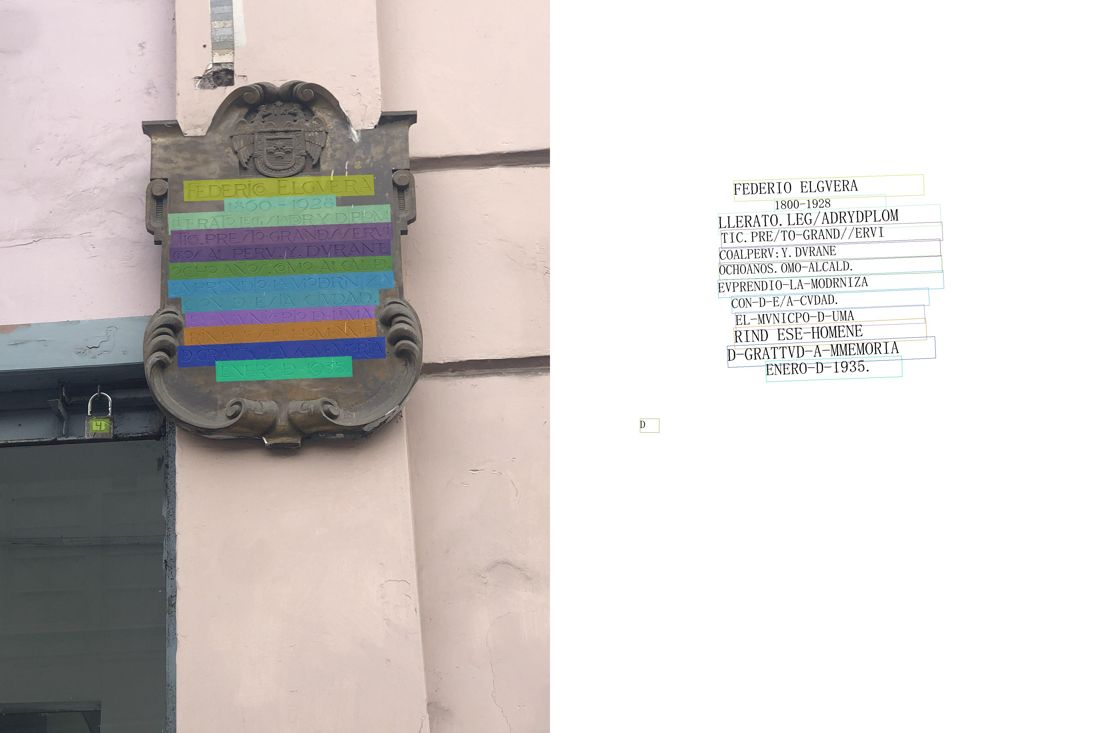

In [5]:
img = Image.open(ex.DOCS / "recortes/doc_010/doc_010_ocr_res_img.jpg").convert("RGB")
img.thumbnail((1100, 1100))
buf = BytesIO()
img.save(buf, format="JPEG", quality=80)
display(Imagen(data=buf.getvalue(), format="jpeg"))

## 4. ASR de los 23 clips (Sesión 13)

El pipeline usa las herramientas de `voz.py`, copiadas sin cambios de la sesión 13:

1. **VAD**: `faster-whisper` con `vad_filter=True` (Silero). Solo le llega audio con voz al modelo, lo que evita que Whisper "alucine" frases en silencios o ruido.
2. **Transcripción**: faster-whisper `small` en CPU (int8), idioma `es`, beam 5. Es la misma configuración que la línea base de la Parte 2.
3. **Diarización**: `voz.diarizar` calcula una huella de voz (WeSpeaker) por segmento y las agrupa sin saber cuántas personas hay. Un umbral de distancia coseno de 0,7 decide cuándo dos voces son distintas.
4. **Exportación**: por cada clip quedan en `datos/raw/audio/asr/` un JSON (segmentos con tiempos y hablante), un **CSV** de segmentos, un **SRT** (subtítulos) y un **TXT** (turnos para leer). El corpus completo va a `datos/transcripciones.csv`.

`voz.py` trae por defecto Whisper turbo. `extraccion.cargar_asr()` cambia en tiempo de ejecución el modelo de la entrada `faster-whisper` por `small`, sin editar `voz.py`.

In [6]:
pendientes = [i for i in clips.id if not (ex.AUDIO / "asr" / f"{i}.json").exists()]
modelo_asr = ex.cargar_asr() if pendientes else None
asr = {i: ex.transcribir_clip(i, modelo_asr) for i in clips.id}

for i, r in asr.items():                                      # exportación CSV por clip (además de SRT y TXT)
    pd.DataFrame(r["segmentos"]).to_csv(ex.AUDIO / "asr" / f"{i}.csv", index=False)

clips["voz_seg"] = clips.id.map(lambda i: asr[i]["voz_seg"])
clips["pct_voz"] = (100 * clips.voz_seg / clips.duracion_seg).round(1)
clips["segundos_asr"] = clips.id.map(lambda i: asr[i]["segundos_asr"])
clips["factor_tiempo_real"] = (clips.segundos_asr / clips.duracion_seg).round(2)
clips["segmentos"] = clips.id.map(lambda i: len(asr[i]["segmentos"]))
clips["n_hablantes"] = clips.id.map(lambda i: len({s["hablante"] for s in asr[i]["segmentos"]}))

print(f"Audio: {clips.duracion_seg.sum() / 60:.1f} min · procesado en {clips.segundos_asr.sum() / 60:.1f} min "
      f"(factor de tiempo real medio {clips.factor_tiempo_real.mean():.2f}) · diarización: "
      f"{sum(r['segundos_diarizacion'] for r in asr.values()) / 60:.1f} min")
clips[["id", "descripcion", "duracion_seg", "pct_voz", "factor_tiempo_real", "segmentos", "n_hablantes"]]

Audio: 42.4 min · procesado en 16.1 min (factor de tiempo real medio 0.37) · diarización: 1.7 min


,id,descripcion,duracion_seg,pct_voz,factor_tiempo_real,segmentos,n_hablantes
0,clip_001,entrevista en la calle,136.3,77.4,0.32,24,2
1,clip_002,"entrevista en la calle, varias hablantes",189.0,82.9,0.35,29,1
2,clip_003,"entrevista durante un partido, ruido de fondo",29.9,91.3,0.39,9,2
3,clip_004,entrevista grabada por estudiante UNMSM,196.0,90.2,0.45,46,2
4,clip_005,entrevista grabada por estudiante UNMSM,96.1,85.4,0.32,16,2
5,clip_006,entrevista grabada por estudiante UNMSM,77.4,87.1,0.40,25,5
6,clip_007,entrevista grabada por estudiante UNMSM,163.9,85.8,0.34,29,3
7,clip_008,"entrevista en una marcha, ruido de multitud",54.3,93.0,0.42,27,12
8,clip_009,"entrevista en una marcha, ruido de multitud",77.4,91.1,0.31,17,2
9,clip_010,"entrevistas en una marcha, ruido de multitud",95.0,70.5,0.38,24,8


Ejemplo de las salidas, primeros subtítulos del SRT de clip_005. La primera pregunta del entrevistador es si la persona está de acuerdo con que la entrevista se publique en internet. Así registran el consentimiento las entrevistas de estudiantes de la UNMSM que se subieron a Commons. El nombre ya aparece seudonimizado (ver la sección 6).

In [7]:
REEMPLAZOS = json.loads((DATOS / "raw/seudonimos.json").read_text(encoding="utf-8"))   # no versionado: tiene los nombres reales
srt = (ex.AUDIO / "asr/clip_005.srt").read_text(encoding="utf-8")
print(voz.seudonimizar("\n".join(srt.splitlines()[:16]), REEMPLAZOS["clip_005"]))

1
00:00:00,620 --> 00:00:06,870
[H1] Nos encontramos aquí.

2
00:00:06,870 --> 00:00:14,290
[H1] Buenas noches, nos encontramos aquí con el señor [ENTREVISTADO_2].

3
00:00:14,290 --> 00:00:20,290
[H1] Señor [ENTREVISTADO_2], esta entrevista va a ser subida en internet, ¿está usted de acuerdo con eso?

4
00:00:20,290 --> 00:00:26,580
[H1] Sí, muchas gracias. La primera pregunta es, ¿qué significa el Perú para usted?



### Diarización: ¿cuántas voces encuentra?

La diarización automática no sabe cuántas personas hablan. Para revisarla hay una referencia humana: en las transcripciones manuales de los 10 clips de la muestra de evaluación (Parte 2) marqué a cada hablante (`h1:`, `h2:`…) al escuchar. Esta tabla compara ambos conteos. No se cambió ningún parámetro del ASR a partir de ella.

In [8]:
manual = {p.stem: len(set(re.findall(r"^h(\d+)[:.]", p.read_text(encoding="utf-8"), flags=re.M)))
          for p in sorted((DATOS / "referencias").glob("clip_*.txt"))}
diar = clips.set_index("id").loc[list(manual), ["descripcion", "n_hablantes"]].rename(columns={"n_hablantes": "detectados"})
diar.insert(1, "manual", pd.Series(manual))
diar["coincide"] = diar.manual == diar.detectados
print(f"Coinciden {diar.coincide.sum()} de {len(diar)}")
diar

Coinciden 5 de 10


,descripcion,manual,detectados,coincide
id,,,,
clip_001,entrevista en la calle,2,2,True
clip_002,"entrevista en la calle, varias hablantes",3,1,False
clip_003,"entrevista durante un partido, ruido de fondo",2,2,True
clip_006,entrevista grabada por estudiante UNMSM,2,5,False
clip_008,"entrevista en una marcha, ruido de multitud",2,12,False
clip_009,"entrevista en una marcha, ruido de multitud",3,2,False
clip_013,entrevista en una fiesta patronal (Áncash),2,3,False
clip_015,entrevista en una fiesta patronal (Áncash),1,1,True
clip_016,lectura de artículo de Wikipedia,1,1,True


In [9]:
# clip_002: tres voces (entrevistador y dos señoras). Sin conocer el número, el umbral las junta en una sola.
# Con el número de hablantes que da la escucha humana (n_hablantes=3), la misma función sí separa los turnos.
audio_002 = voz.cargar_audio(ex.AUDIO / "clip_002.wav")
con_3 = voz.diarizar(audio_002, ex.segmentos_de(asr["clip_002"]), n_hablantes=3, device="cpu")
print(voz.seudonimizar(voz.a_texto(con_3), REEMPLAZOS["clip_002"])[:1300])

[00:00:00] H1: Buenos días profesor y compañeros. Hoy estoy cerca de aquí por mi casa y voy a hacer entrevistas cerca del fútbol como unión de masas. Estoy con las señoras [ENTREVISTADA_7]. ¿Estáis [ENTREVISTADA_8]? Muy bien. Voy a comenzar con la primera pregunta y es ¿qué expectativas tienen ante este partido?

[00:00:22] H2: Que la afición se encuentra motivado para ganar este partido. ¿Me puede decir su nombre? [ENTREVISTADA_7].

[00:00:33] H3: La expectativa que pienso es que acá que el Perú va a dar todo por todo, todo su corazón va a entregar para que ganemos ¿no? para que seamos ganemos este para ir a las

[00:00:46] H1: olimpiadas al mundial. ¿Me puede decir este su nombre? [ENTREVISTADA_8]. Bien. Sigo con la siguiente pregunta. ¿Qué jugador piensa que va a ser más determinante? Antes de que diga su respuesta

[00:01:02] H2: dígame su nombre por favor. [ENTREVISTADA_7]. La padula. ¿Por qué? Porque ha demostrado su fuerza y su barra para jugar y ha metido unos

[00:01:18] H1: c

**Lectura.** Con el umbral fijo de 0,7, la diarización acierta en 5 de 10 clips: las dos lecturas, el testimonio de una sola persona y dos entrevistas de dos voces. Cuando falla, lo hace en ambas direcciones:
- **Junta voces:** en clip_002 las tres voces se agrupan en una sola, porque son voces parecidas grabadas en la calle con el mismo micrófono. En clip_009 encuentra 2 voces donde hay 3.
- **Parte voces:** separa a una misma persona en varios "hablantes" cuando hay ruido de multitud o cambios de volumen: 12 en clip_008, 5 en clip_006 y 3 en clip_013, donde se escuchan 2.

Si se le da el número de hablantes (`n_hablantes=3`), en clip_002 aparecen las tres voces y los turnos se alternan como en la entrevista. Aun así, algunos turnos mezclan el final de una pregunta con el inicio de la respuesta: la diarización pone **un hablante por segmento de Whisper**, y Whisper no corta donde cambia la voz. La columna `n_hablantes` del CSV guarda **lo que detectó la diarización automática**, para no mezclar métodos. Esta revisión muestra que en audio de calle ese número es solo orientativo.

### Audios con poca voz

In [10]:
poca_voz = clips[clips.pct_voz < 25][["id", "descripcion", "duracion_seg", "voz_seg", "pct_voz"]]
poca_voz

,id,descripcion,duracion_seg,voz_seg,pct_voz
13,clip_014,entrevista en una fiesta patronal (Áncash),98.3,10.6,10.8


**clip_014** tiene voz detectable solo en 10,6 de sus 98 s, aunque el nivel del audio es alto y parejo de principio a fin. Al escucharlo se comprobó que **sí hay conversación durante todo el clip, pero una banda de música de la fiesta patronal la tapa**. El VAD de Silero no separa el habla de la música, así que descarta casi todo el clip, y Whisper solo transcribe los primeros segundos.

Como hay información hablada, **no se descarta**. Queda en el corpus como el caso difícil de **audio con música** que analiza la Parte 2, sin cambiar ningún parámetro para "rescatarlo". Su `texto_asr` es parcial, y así se documenta.

In [11]:
# Audios sin voz confirmados al escucharlos: ninguno (clip_014 tiene habla bajo la música y se conserva)
SIN_VOZ = {}
DESCARTES = pd.DataFrame(
    [{"id": i, "modalidad": "audio", "motivo": m} for i, m in SIN_VOZ.items()]
    + [{"id": i, "modalidad": "documento", "motivo": "el OCR no detectó texto"} for i in ilegibles.id],
    columns=["id", "modalidad", "motivo"])
clips = clips[~clips.id.isin(DESCARTES.id)].reset_index(drop=True)
docs = docs[~docs.id.isin(DESCARTES.id)].reset_index(drop=True)

print(f"Descartados: {len(DESCARTES)} · quedan {len(docs)} documentos y {len(clips)} clips con {clips.duracion_seg.sum() / 60:.1f} min de audio")
print(f"Mínimos de la tarea: ≥25 documentos → {len(docs) >= 25} · ≥20 clips → {len(clips) >= 20} · ≥30 min → {clips.duracion_seg.sum() >= 1800}")
DESCARTES

Descartados: 0 · quedan 25 documentos y 23 clips con 42.4 min de audio
Mínimos de la tarea: ≥25 documentos → True · ≥20 clips → True · ≥30 min → True


,id,modalidad,motivo


## 5. Texto ASR con marcas de hablante

Para el CSV, los segmentos seguidos de una misma voz se unen en un turno marcado como `[HABLANTE_n]`, en el mismo formato que el enunciado. En la Parte 2 esas marcas se quitan antes de calcular el WER, porque no son palabras habladas.

In [12]:
def texto_con_hablantes(segmentos):
    turnos = []
    for s in segmentos:
        h = "HABLANTE_" + s["hablante"].lstrip("H")
        if turnos and turnos[-1][0] == h:
            turnos[-1][1].append(s["texto"])
        else:
            turnos.append((h, [s["texto"]]))
    return "\n".join(f"[{h}] {' '.join(t)}" for h, t in turnos)


clips["texto_asr_crudo"] = clips.id.map(lambda i: texto_con_hablantes(asr[i]["segmentos"]))
# se imprime ya seudonimizado: el texto crudo nunca se muestra ni se exporta
print(voz.seudonimizar(clips.loc[clips.id == "clip_001", "texto_asr_crudo"].item(), REEMPLAZOS["clip_001"])[:500])

[HABLANTE_1] Buenos días, aquí son las 10 y 28 y estoy con una señora que va a darme su opinión acerca de partido de hoy. ¿Puedes decirme su nombre por favor?
[HABLANTE_2] [ENTREVISTADA_6].
[HABLANTE_1] Mucho gusto, yo soy [ENTREVISTADOR_1], soy alumno de la Universidad Nacional Mayor de San Marcos y le voy a hacer estas preguntas acerca del partido de hoy. ¿Qué expectativas tiene acerca de este partido? ¿Quién piensa que va a atacar más o defender?
[HABLANTE_2] Bueno, esperamos que Perú ganemos


## 6. Seudonimización

**Criterio** (decidido antes de revisar los textos):
- **Se seudonimiza** a las personas privadas: entrevistadas y entrevistados, los estudiantes que hacen las entrevistas, la persona homenajeada en una resolución municipal y un familiar mencionado en El Peruano.
- **Se conservan** las figuras históricas fallecidas (Grau, Piérola, Palma…), los funcionarios en el ejercicio de su cargo (ministros, jueces, presidentes) y las figuras públicas citadas (futbolistas, arqueólogos).
- Los autores de los archivos en Commons siguen en la columna `autor` de `fuentes.csv`, porque la licencia CC BY-SA obliga a atribuirlos. Aun así, en las transcripciones también se seudonimizan, para publicar lo mínimo.

**Procedimiento:**
1. **Detección automática.** El NER en español (`mrm8488/bert-spanish-cased-finetuned-ner`) marca cada entidad de tipo persona en los 48 textos.
2. **Revisión humana.** Se revisó cada candidato en su contexto, y además se buscaron autopresentaciones ("mi nombre es…", "soy…") que el NER no detectó o que el ASR escribió deformadas (un apellido partido en dos palabras, o un nombre convertido en una palabra común).
3. **Reemplazo.** Se aplica `voz.seudonimizar`, que usa comparación difusa y por eso también atrapa nombres mal transcritos. El diccionario se arma **por archivo**, porque un mismo nombre de pila puede ser dos personas distintas en dos clips. Como contiene los nombres reales, vive en `datos/raw/seudonimos.json`, que no se versiona. Aquí solo se muestran las etiquetas.

In [13]:
from transformers import logging as tlog, pipeline
tlog.set_verbosity_error()
ner = pipeline("ner", model="mrm8488/bert-spanish-cased-finetuned-ner", aggregation_strategy="simple", device="cpu")


def personas(texto, paso=600):
    "Entidades PER del NER (por trozos: BERT acepta hasta 512 tokens)."
    trozos = [texto[i:i + paso + 100] for i in range(0, len(texto), paso)]
    return {e["word"] for t in trozos for e in ner(t) if e["entity_group"] == "PER" and e["score"] > 0.6 and len(e["word"]) > 2}


textos = {**dict(zip(docs.id, docs.texto_ocr_crudo)), **dict(zip(clips.id, clips.texto_asr_crudo))}
candidatos = {i: personas(t) for i, t in textos.items()}
print(f"Candidatos PER del NER: {sum(map(len, candidatos.values()))} en {sum(bool(c) for c in candidatos.values())} de {len(textos)} textos")
print(f"(sin mostrar los nombres: la mayoría son figuras públicas o históricas, o fragmentos de palabras mal leídas)")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Candidatos PER del NER: 135 en 35 de 48 textos
(sin mostrar los nombres: la mayoría son figuras públicas o históricas, o fragmentos de palabras mal leídas)


In [14]:
ETIQUETA = re.compile(r"\[(?:ENTREVISTAD[OA]R?|HOMENAJEADO|PERSONA)_\d+\]")


def seudonimizar(id_, texto):
    "Devuelve el texto seudonimizado y cuántas menciones se reemplazaron."
    limpio = voz.seudonimizar(texto, REEMPLAZOS.get(id_, {}))
    return limpio, len(ETIQUETA.findall(limpio)) - len(ETIQUETA.findall(texto))


docs[["texto_ocr", "reemplazos"]] = [seudonimizar(i, t) for i, t in zip(docs.id, docs.texto_ocr_crudo)]
clips[["texto_asr", "reemplazos"]] = [seudonimizar(i, t) for i, t in zip(clips.id, clips.texto_asr_crudo)]

reemplazos = pd.concat([docs[["id", "reemplazos"]], clips[["id", "reemplazos"]]]).query("reemplazos > 0")
personas_unicas = {e for d in REEMPLAZOS.values() for e in d.values()}
print(f"Menciones reemplazadas: {reemplazos.reemplazos.sum()} en {len(reemplazos)} archivos · personas distintas seudonimizadas: {len(personas_unicas)}")
display(pd.Series(sorted(personas_unicas)).str.extract(r"\[(\w+?)_\d+\]")[0].value_counts().rename("personas"))
reemplazos.set_index("id").T

Menciones reemplazadas: 35 en 14 archivos · personas distintas seudonimizadas: 19


0
ENTREVISTADA     8
ENTREVISTADO     5
ENTREVISTADOR    4
HOMENAJEADO      1
PERSONA          1
Name: personas, dtype: int64

id,doc_003,doc_004,clip_001,clip_002,clip_004,clip_005,clip_006,clip_007,clip_008,clip_009,clip_010,clip_011,clip_012,clip_013
reemplazos,2,1,2,10,4,2,1,3,1,2,2,2,2,1


In [15]:
# Control final: ningún nombre del diccionario debe sobrevivir en los textos publicados
reales = {n.lower() for d in REEMPLAZOS.values() for nombre in d for n in nombre.split() if len(n) > 3}
fugas = {i: [w for w in re.findall(r"\w+", t.lower()) if w in reales]
         for i, t in [*zip(docs.id, docs.texto_ocr), *zip(clips.id, clips.texto_asr)]}
fugas = {i: len(w) for i, w in fugas.items() if w}
print("Palabras de nombres reales que siguen en los textos:", fugas or "ninguna")

Palabras de nombres reales que siguen en los textos: {'doc_004': 4, 'doc_006': 2, 'doc_009': 1, 'doc_014': 2, 'doc_020': 1, 'clip_022': 2}


Las coincidencias que quedan se revisaron una por una en su contexto y **no son las personas seudonimizadas**: coinciden por nombre de pila o apellido con otras figuras que el criterio conserva.
- **doc_004:** jueces y síndicos nombrados en El Peruano.
- **doc_006:** el "gabinete Romero" de 1909.
- **doc_009 y doc_014:** el papa Juan Pablo II y el cardenal Landázuri.
- **doc_020:** un funcionario de 1894.
- **clip_022:** el distrito de San Juan de Lurigancho.

## 7. Análisis exploratorio

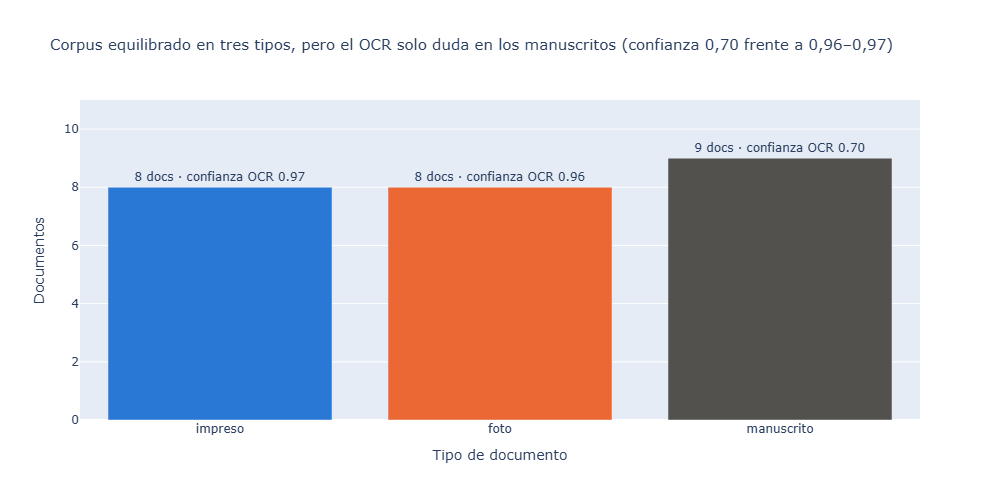

In [16]:
docs["caracteres"] = docs.texto_ocr.str.len()
clips["palabras"] = clips.texto_asr.str.replace(r"\[HABLANTE_\d+\]", "", regex=True).str.split().str.len()

por_tipo = docs.groupby("tipo").agg(documentos=("id", "size"), confianza=("confianza_media", "mean")).reindex(["impreso", "foto", "manuscrito"]).reset_index()
por_tipo["etiqueta"] = por_tipo.apply(lambda f: f"{f.documentos} docs · confianza OCR {f.confianza:.2f}", axis=1)
fig = px.bar(por_tipo, x="tipo", y="documentos", color="tipo", text="etiqueta", color_discrete_map=COLORES,
             title="Corpus equilibrado en tres tipos, pero el OCR solo duda en los manuscritos (confianza 0,70 frente a 0,96–0,97)",
             labels={"tipo": "Tipo de documento", "documentos": "Documentos"})
fig.update_traces(textposition="outside").update_layout(showlegend=False, yaxis_range=[0, 11], title_font_size=15)
fig.show()

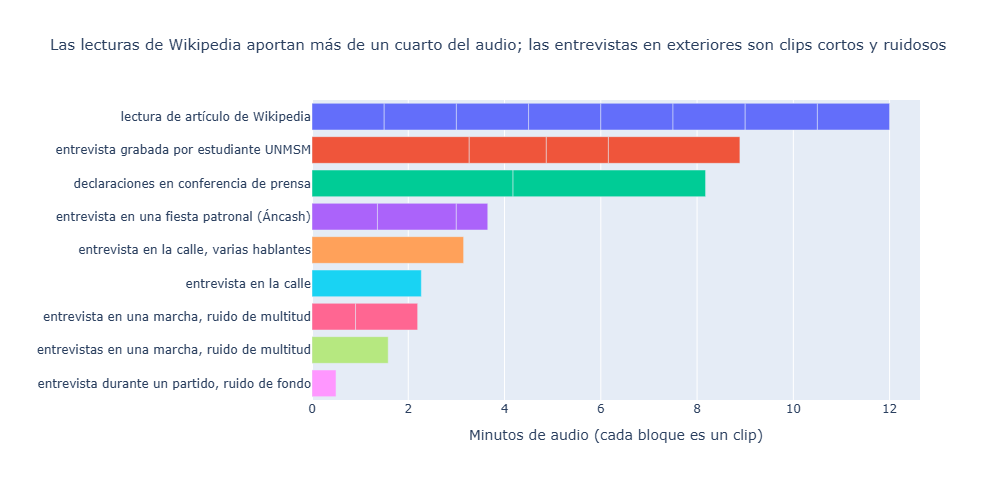

In [17]:
orden = clips.groupby("descripcion").duracion_seg.sum().sort_values().index
fig = px.bar(clips.assign(minutos=clips.duracion_seg / 60), x="minutos", y="descripcion", color="descripcion", hover_name="id",
             category_orders={"descripcion": list(orden)[::-1]},
             title="Las lecturas de Wikipedia aportan más de un cuarto del audio; las entrevistas en exteriores son clips cortos y ruidosos",
             labels={"minutos": "Minutos de audio (cada bloque es un clip)", "descripcion": ""})
fig.update_layout(showlegend=False, title_font_size=15, height=480)
fig.show()

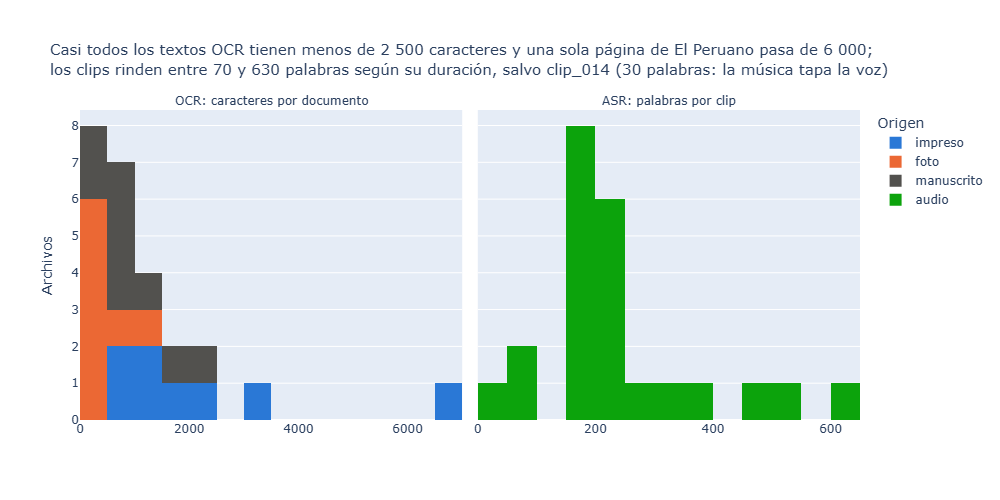

In [18]:
largos = pd.concat([
    pd.DataFrame({"id": docs.id, "medida": "OCR: caracteres por documento", "valor": docs.caracteres, "grupo": docs.tipo}),
    pd.DataFrame({"id": clips.id, "medida": "ASR: palabras por clip", "valor": clips.palabras, "grupo": "audio"}),
])
fig = px.histogram(largos, x="valor", facet_col="medida", color="grupo", hover_data=["id"],
                   color_discrete_map={**COLORES, "audio": "#0ca30c"},
                   title="Casi todos los textos OCR tienen menos de 2 500 caracteres y una sola página de El Peruano pasa de 6 000;"
                         "<br>los clips rinden entre 70 y 630 palabras según su duración, salvo clip_014 (30 palabras: la música tapa la voz)",
                   labels={"valor": "", "grupo": "Origen"})
# cada panel con sus propios intervalos: 500 caracteres en OCR, 50 palabras en ASR
fig.for_each_trace(lambda t: t.update(bingroup=None, xbins=dict(start=0, size=50 if t.name == "audio" else 500)))
fig.update_xaxes(matches=None).for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.update_layout(title_font_size=15, yaxis_title="Archivos", barmode="stack", margin_t=110)
fig.show()

## 8. Validación: extremos de longitud

Los 3 documentos con el OCR más largo y más corto, y los 3 clips más largos y más cortos, para comprobar que coinciden con las colas de los histogramas y que su texto tiene sentido.

In [19]:
def extremos(df, col, cols):
    return pd.concat([df.nlargest(3, col).assign(extremo="más largo"), df.nsmallest(3, col).assign(extremo="más corto")])[["extremo", *cols]]


docs["inicio_texto"] = docs.texto_ocr.str.replace("\n", " · ").str[:90]
extremos(docs, "caracteres", ["id", "tipo", "descripcion", "caracteres", "inicio_texto"])

,extremo,id,tipo,descripcion,caracteres,inicio_texto
3,más largo,doc_004,impreso,Página de normas legales de El Peruano (2006),6514,"El Paruano · Lima, miércoles 6 de diciembre de 2006 · NORMAS LEGALES · 334095 · expedido p"
5,más largo,doc_006,impreso,Revista Variedades N.° 67 (1909),3020,"Año V · Lima, 12 de junio de 1909 · N.67 · Sucesora de ""PRISMA"" · Premiado con Medalla de"
24,más largo,doc_025,manuscrito,"Decreto del Virrey del Perú, Marqués de Mancera (1642)",2436,54 · dd · Comendaler deesparmagal enlaarin deal cantara genat Eombre desumag · Suconsel de
23,más corto,doc_024,manuscrito,Nota de José Balta (1869),152,"$30 · I'Lor t. Antinic Ser Hami · Aregripa · Chirriles, abril o fey · IRrel lportaiora te"
11,más corto,doc_012,foto,Placa de mármol en un muro pintado,160,SEINAUGURARONLOS · MERCADOS MAYORISTA YMINORISTA · SIENDO PRESIDENTE DE LA REPUBLICA · ELS
10,más corto,doc_011,foto,Placa oscura en una pared del Centro de Lima,165,LA CIVDAD DE LIMA · AL SEVILLANO · FRAY · DIEGO DE · HOJEDA OP · (1570 - 1615) · AVTOR DEL


In [20]:
clips["inicio_texto"] = clips.texto_asr.str.replace("\n", " ").str[:90]
extremos(clips, "duracion_seg", ["id", "descripcion", "duracion_seg", "palabras", "inicio_texto"])

,extremo,id,descripcion,duracion_seg,palabras,inicio_texto
10,más largo,clip_011,declaraciones en conferencia de prensa,250.6,628,"[HABLANTE_1] Bueno, hola, estamos en la San Martín, entre Fritas Patreas, 28 de julio. Ent"
11,más largo,clip_012,declaraciones en conferencia de prensa,240.0,533,"[HABLANTE_1] ¿Qué esperamos? [HABLANTE_2] Bien, estamos en Plata San Martín. Antes que nad"
3,más largo,clip_004,entrevista grabada por estudiante UNMSM,196.0,485,"[HABLANTE_1] Buenas noches, primeramente es mi nombre [ENTREVISTADOR_2], soy estudiante de"
2,más corto,clip_003,"entrevista durante un partido, ruido de fondo",29.9,69,"[HABLANTE_1] Normal, pero no lo resultaba, no es verdad? [HABLANTE_2] Pero como lo ves? Co"
14,más corto,clip_015,entrevista en una fiesta patronal (Áncash),39.2,73,"[HABLANTE_1] Buenos días, joven. Claro que sí, la fiesta de santo patrón de Chuia-Staitapa"
7,más corto,clip_008,"entrevista en una marcha, ruido de multitud",54.3,164,"[HABLANTE_1] Sí, déjalo ya, así está la banda. ¿Qué ayuda? [HABLANTE_2] Ya está la banda."


**Coherencia con los histogramas:**
- **OCR, cola derecha:** la ocupa doc_004, una página completa de normas legales de El Peruano (más de 6 000 caracteres), seguida de la revista Variedades (doc_006).
- **OCR, extremo corto:** son placas y un manuscrito breve (doc_024), de 150 a 170 caracteres. Coinciden con la primera barra del histograma.
- **ASR:** los clips más largos (las dos declaraciones de 4 min) son también los que más palabras tienen, unas 530 y 630. Los más cortos son entrevistas al paso de 30 a 54 s, con 69 a 164 palabras: la columna izquierda del histograma de audio.

En el histograma de audio, la primera barra (0–50 palabras) es **clip_014** sola: dura 98 s pero rinde solo 30 palabras, porque la banda de música tapa las voces (sección 2). La siguiente barra (50–100) corresponde a los dos clips más cortos, clip_003 y clip_015.

No hay textos vacíos ni la repetición en bucle típica de las alucinaciones de Whisper. Pero **longitud no es calidad**: el decreto virreinal de 1642 (doc_025) es el tercer texto más largo y casi todo es ilegible ("Comendaler deesparmagal…"). Lo mismo pasa con la nota de Balta (doc_024), en el extremo corto. La letra manuscrita antigua produce texto abundante pero sin sentido, y el CER de la Parte 2 lo medirá.

## 9. Exportación

`texto_referencia` queda vacío por ahora. Se completa en la Parte 2 con mis transcripciones manuales de la muestra de evaluación (10 documentos y 10 clips), seudonimizadas con el mismo diccionario.

In [21]:
fuente = lambda lic: f"Wikimedia Commons ({lic})"

documentos = docs.assign(fuente=docs.licencia.map(fuente), modelo_ocr=ex.nombre_modelo_ocr(), texto_referencia="")[
    ["id", "archivo", "tipo", "fuente", "texto_ocr", "modelo_ocr", "texto_referencia",
     "descripcion", "lineas", "confianza_media", "caracteres", "segundos_ocr"]]
transcripciones = clips.assign(idioma="es", modelo_asr=ex.nombre_modelo_asr(), texto_referencia="", fuente=clips.licencia.map(fuente))[
    ["id", "archivo_audio", "duracion_seg", "idioma", "texto_asr", "modelo_asr", "n_hablantes", "texto_referencia",
     "descripcion", "fuente", "recorte", "voz_seg", "palabras", "segundos_asr", "factor_tiempo_real"]]

documentos.to_csv(DATOS / "documentos.csv", index=False)
transcripciones.to_csv(DATOS / "transcripciones.csv", index=False)
fuentes.to_csv(DATOS / "fuentes.csv", index=False)

for nombre, df in [("documentos", documentos), ("transcripciones", transcripciones), ("fuentes", fuentes)]:
    print(f"datos/{nombre}.csv: {df.shape}")

datos/documentos.csv: (25, 12)
datos/transcripciones.csv: (23, 15)
datos/fuentes.csv: (48, 8)


In [22]:
documentos.head(5)

,id,archivo,tipo,fuente,texto_ocr,modelo_ocr,texto_referencia,descripcion,lineas,confianza_media,caracteres,segundos_ocr
0,doc_001,datos/raw/documentos/doc_001.jpg,impreso,Wikimedia Commons (CC BY-SA 4.0),Representación Permanente del Periv ante\nRECEIVED\nla Organización de los Estados Americanos\n0926\n2001 ...,"PaddleOCR 3.7.0 (PP-OCRv6_medium_det + PP-OCRv6_medium_rec, CPU, sin preprocesamiento)",,Nota de la Representación del Perú ante la OEA (2001),31,0.967,1043,32.5
1,doc_002,datos/raw/documentos/doc_002.jpg,impreso,Wikimedia Commons (CC0),"Secretaria General de la Presidencia\nde la República\nLima, 19 de diciembre de 1956\nSeñor\nSegundo Galla...","PaddleOCR 3.7.0 (PP-OCRv6_medium_det + PP-OCRv6_medium_rec, CPU, sin preprocesamiento)",,Carta mecanografiada de la Secretaría de la Presidencia (1956),20,0.963,577,24.1
2,doc_003,datos/raw/documentos/doc_003.jpg,impreso,Wikimedia Commons (CC0),MUNICIPALIDAD PROVINCIAL DE\nMOYOBAMBA\nCAPITALDELDEPARTAMENTO DESANMARTÍN\n“Año de la Diversificación Pro...,"PaddleOCR 3.7.0 (PP-OCRv6_medium_det + PP-OCRv6_medium_rec, CPU, sin preprocesamiento)",,Resolución de alcaldía de Moyobamba (2015),40,0.968,2143,60.0
3,doc_004,datos/raw/documentos/doc_004.jpg,impreso,Wikimedia Commons (CC BY-SA 4.0),"El Paruano\nLima, miércoles 6 de diciembre de 2006\nNORMAS LEGALES\n334095\nexpedido por el Jefe del Servi...","PaddleOCR 3.7.0 (PP-OCRv6_medium_det + PP-OCRv6_medium_rec, CPU, sin preprocesamiento)",,Página de normas legales de El Peruano (2006),142,0.991,6514,123.4
4,doc_005,datos/raw/documentos/doc_005.jpg,impreso,Wikimedia Commons (Public domain),"EL LIBERTADOR BANON GASTILLA,\nGRAN MARISCALDELOSEJERCITOS,\nCONDECORADO-CONLAS MEDALLASDEJUNIN,\nAYACUCHO...","PaddleOCR 3.7.0 (PP-OCRv6_medium_det + PP-OCRv6_medium_rec, CPU, sin preprocesamiento)",,"Constitución de 1856, página impresa",23,0.940,762,15.9


In [23]:
transcripciones.head(5)

,id,archivo_audio,duracion_seg,idioma,texto_asr,modelo_asr,n_hablantes,texto_referencia,descripcion,fuente,recorte,voz_seg,palabras,segundos_asr,factor_tiempo_real
0,clip_001,datos/raw/audio/clip_001.wav,136.3,es,"[HABLANTE_1] Buenos días, aquí son las 10 y 28 y estoy con una señora que va a darme su opinión acerca de ...","faster-whisper 1.2.1 small (CPU int8, beam 5, VAD Silero on, idioma=es)",2,,entrevista en la calle,Wikimedia Commons (CC BY-SA 4.0),completo,105.5,257,43.4,0.32
1,clip_002,datos/raw/audio/clip_002.wav,189.0,es,[HABLANTE_1] Buenos días profesor y compañeros. Hoy estoy cerca de aquí por mi casa y voy a hacer entrevis...,"faster-whisper 1.2.1 small (CPU int8, beam 5, VAD Silero on, idioma=es)",1,,"entrevista en la calle, varias hablantes",Wikimedia Commons (CC BY-SA 4.0),completo,156.6,353,66.2,0.35
2,clip_003,datos/raw/audio/clip_003.wav,29.9,es,"[HABLANTE_1] Normal, pero no lo resultaba, no es verdad?\n[HABLANTE_2] Pero como lo ves? Como ves a Perú a...","faster-whisper 1.2.1 small (CPU int8, beam 5, VAD Silero on, idioma=es)",2,,"entrevista durante un partido, ruido de fondo",Wikimedia Commons (CC BY-SA 4.0),completo,27.3,69,11.7,0.39
3,clip_004,datos/raw/audio/clip_004.wav,196.0,es,"[HABLANTE_1] Buenas noches, primeramente es mi nombre [ENTREVISTADOR_2], soy estudiante de la Universidad ...","faster-whisper 1.2.1 small (CPU int8, beam 5, VAD Silero on, idioma=es)",2,,entrevista grabada por estudiante UNMSM,Wikimedia Commons (CC BY-SA 4.0),completo,176.7,485,88.8,0.45
4,clip_005,datos/raw/audio/clip_005.wav,96.1,es,"[HABLANTE_1] Nos encontramos aquí. Buenas noches, nos encontramos aquí con el señor [ENTREVISTADO_2]. Seño...","faster-whisper 1.2.1 small (CPU int8, beam 5, VAD Silero on, idioma=es)",2,,entrevista grabada por estudiante UNMSM,Wikimedia Commons (CC BY-SA 4.0),completo,82.1,185,30.7,0.32


In [24]:
fuentes.head(5)

,id,modalidad,fuente_url,licencia,autor,acceso,titulo_original,fecha_descarga
0,doc_001,documento,https://commons.wikimedia.org/wiki/File:Carta_Democr%C3%A1tica_Interamericana.jpg,CC BY-SA 4.0,Elypress,Descarga pública desde Wikimedia Commons; se recupera con `uv run python corpus.py`,Carta Democrática Interamericana.jpg,2026-10-22
1,doc_002,documento,https://commons.wikimedia.org/wiki/File:Carta_de_agradecimiento_del_secretario_de_la_Presidencia_de_la_Rep...,CC0,Anderson Reyes Trillo,Descarga pública desde Wikimedia Commons; se recupera con `uv run python corpus.py`,Carta de agradecimiento del secretario de la Presidencia de la República Nazario Chávez Aliaga al pintor S...,2026-10-22
2,doc_003,documento,https://commons.wikimedia.org/wiki/File:Otorgamiento_Municipal.jpg,CC0,Ing. Oswaldo Jiménez Salas,Descarga pública desde Wikimedia Commons; se recupera con `uv run python corpus.py`,Otorgamiento Municipal.jpg,2026-10-22
3,doc_004,documento,https://commons.wikimedia.org/wiki/File:NOMBRAMIENTO_JAVIER_DAVID_HABICH.pdf,CC BY-SA 4.0,El Peruano,Descarga pública desde Wikimedia Commons; se recupera con `uv run python corpus.py`,NOMBRAMIENTO JAVIER DAVID HABICH.pdf,2026-10-22
4,doc_005,documento,https://commons.wikimedia.org/wiki/File:Constituci%C3%B3n_Pol%C3%ADtica_del_Per%C3%BA_%281856%29.pdf,Public domain,Varios,Descarga pública desde Wikimedia Commons; se recupera con `uv run python corpus.py`,Constitución Política del Perú (1856).pdf,2026-10-22


## Resumen de la Parte 1

| | |
|---|---|
| **Documentos** | 25 (8 impresos, 8 fotos y 9 manuscritos), todos con texto OCR; 0 duplicados, 0 ilegibles |
| **Audio** | 23 clips y 42,4 min (≥1 multihablante); 0 duplicados, 0 descartes. clip_014 se conserva como caso difícil: tiene habla tapada por una banda de música |
| **Diarización** | Automática en los 23 clips; coincide con la escucha humana en 5 de 10. En el multihablante clip_002 solo aparecen las tres voces si se le da el número de hablantes |
| **Seudonimización** | 19 personas privadas, 35 menciones reemplazadas en 14 archivos; nombres reales solo en `datos/raw/` (no versionado) |
| **Exportación** | `documentos.csv`, `transcripciones.csv` y `fuentes.csv`; SRT, TXT, CSV y JSON por clip y OCR crudo por documento en `datos/raw/` |